In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

results = pd.read_csv("../results/model_comparison.csv")

results

,Model,RMSLE
0,Random Forest,0.328139
1,Gradient Boosting,0.452745
2,Linear Regression,1.273642


In [2]:
best_model_name = results.loc[
    results["RMSLE"].idxmin(),
    "Model"
]

best_score = results["RMSLE"].min()

print("Best model:", best_model_name)
print("Best RMSLE:", best_score)

Best model: Random Forest
Best RMSLE: 0.3281389526975628


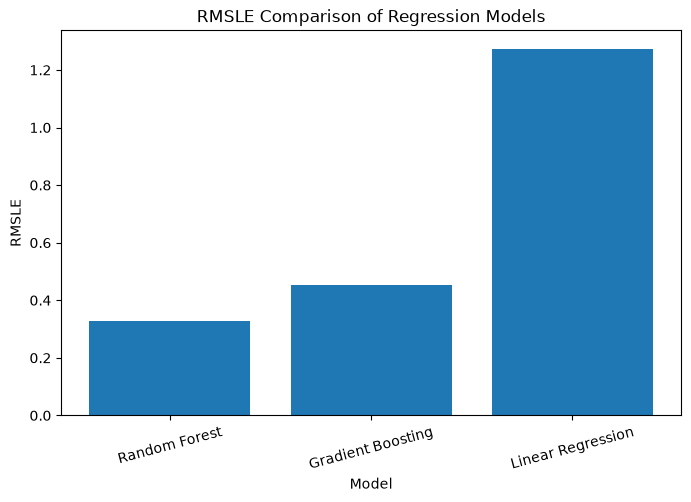

In [3]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    results["Model"],
    results["RMSLE"]
)

plt.xlabel("Model")
plt.ylabel("RMSLE")
plt.title("RMSLE Comparison of Regression Models")
plt.xticks(rotation=15)

plt.show()

In [4]:
from sklearn.model_selection import train_test_split

train = pd.read_csv("../data/train.csv")

train["datetime"] = pd.to_datetime(train["datetime"])

for df in [train]:
    df["year"] = df["datetime"].dt.year
    df["month"] = df["datetime"].dt.month
    df["day"] = df["datetime"].dt.day
    df["hour"] = df["datetime"].dt.hour
    df["day_of_week"] = df["datetime"].dt.dayofweek
    df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

    df["peak_hour"] = (
        (
            (df["day_of_week"] < 5) &
            (df["hour"].isin([7, 8, 9, 17, 18, 19]))
        )
        |
        (
            (df["day_of_week"] >= 5) &
            (df["hour"].between(10, 18))
        )
    ).astype(int)

In [5]:
y = train["count"]

X = train.drop(
    columns=["count", "casual", "registered", "datetime"]
)

X = pd.get_dummies(
    X,
    columns=["season", "weather"],
    drop_first=False
)

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Validation data prepared:", X_valid.shape)

Validation data prepared: (2178, 21)


In [6]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression

In [7]:
if best_model_name == "Linear Regression":
    best_model = LinearRegression()

elif best_model_name == "Random Forest":
    best_model = RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )

elif best_model_name == "Gradient Boosting":
    best_model = GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=5,
        random_state=42
    )

best_model.fit(X_train, y_train)

valid_predictions = best_model.predict(X_valid)

print("Best model retrained successfully.")

Best model retrained successfully.


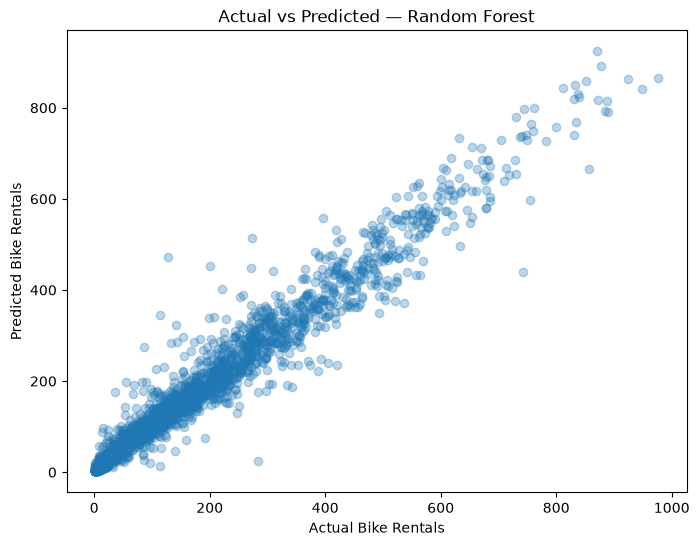

In [8]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_valid,
    valid_predictions,
    alpha=0.3
)

plt.xlabel("Actual Bike Rentals")
plt.ylabel("Predicted Bike Rentals")
plt.title(f"Actual vs Predicted — {best_model_name}")

plt.show()

In [9]:
errors = y_valid - valid_predictions

print("Mean error:", errors.mean())
print("Mean absolute error:", np.abs(errors).mean())

Mean error: -0.0002456382001839011
Mean absolute error: 24.309354912764004


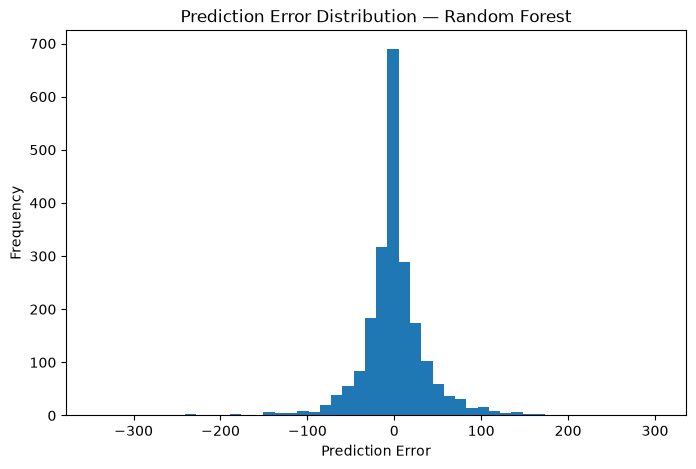

In [10]:
plt.figure(figsize=(8, 5))

plt.hist(errors, bins=50)

plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.title(f"Prediction Error Distribution — {best_model_name}")

plt.show()

In [11]:
if hasattr(best_model, "feature_importances_"):
    importance = pd.DataFrame({
        "Feature": X_train.columns,
        "Importance": best_model.feature_importances_
    })

    importance = importance.sort_values(
        "Importance",
        ascending=False
    )

    importance.head(15)

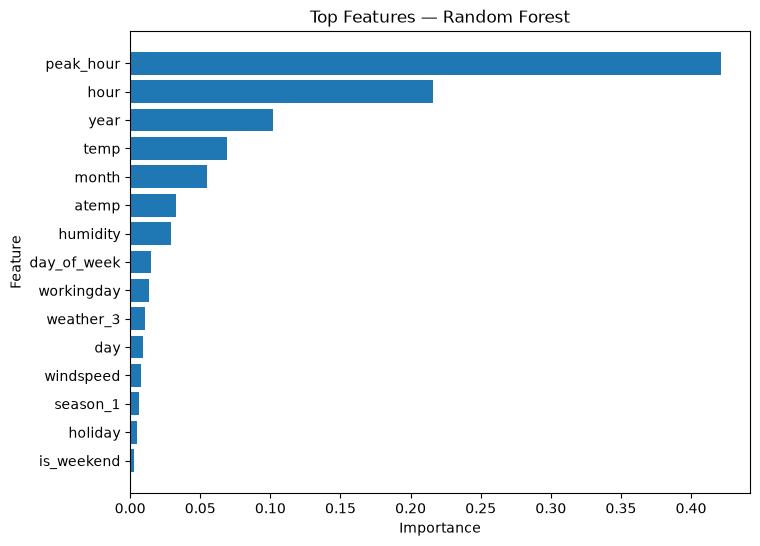

In [12]:
top_features = importance.head(15).sort_values("Importance")

plt.figure(figsize=(8, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title(f"Top Features — {best_model_name}")

plt.show()

In [13]:
evaluation_summary = pd.DataFrame({
    "Model": [best_model_name],
    "RMSLE": [best_score],
    "Mean_Error": [errors.mean()],
    "Mean_Absolute_Error": [np.abs(errors).mean()]
})

evaluation_summary.to_csv(
    "../results/evaluation_summary.csv",
    index=False
)

print("Evaluation results saved.")

Evaluation results saved.
